project root: c:\Users\dariabulacu\Documents\Facultate II-2\IA\ML\ML_Project
train: (15500, 2) | test: (5500, 1)


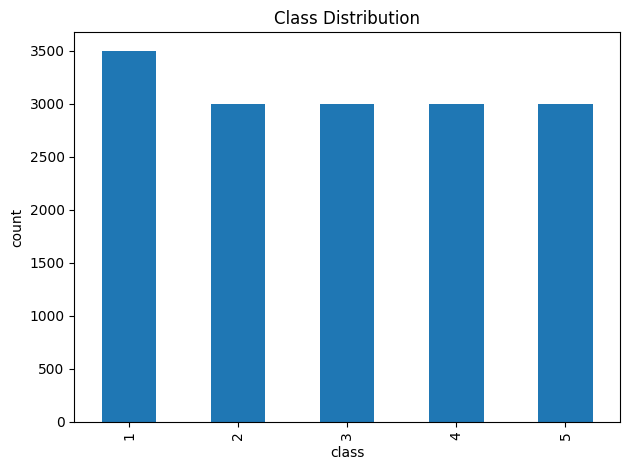

label
1    3500
2    3000
3    3000
4    3000
5    3000
Name: count, dtype: int64


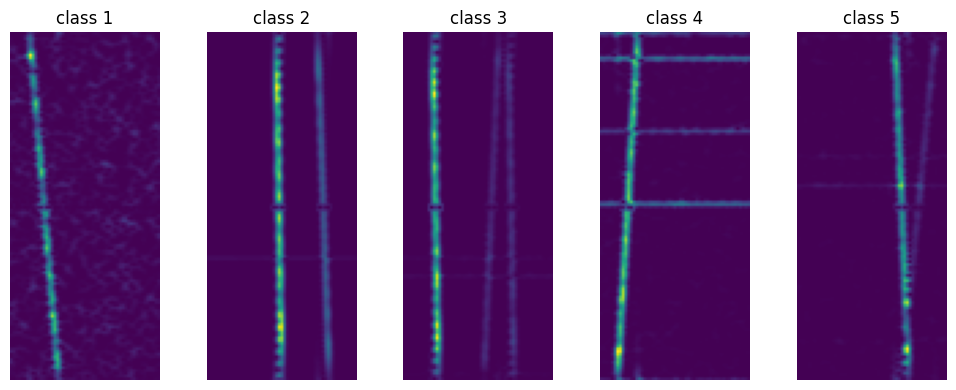

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# --- locate the project root: nearest ancestor of CWD that contains a 'data' folder.
# Robust whether the kernel runs from the project root, from nb/, on Windows,
# WSL, or a cloud kernel (as long as the project tree is accessible).
def find_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    for _ in range(6):
        if os.path.isdir(os.path.join(d, "data")):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            break
        d = parent
    raise FileNotFoundError("could not find project root containing a 'data' folder")

PATH = find_root()
DATA = os.path.join(PATH, "data")
RES  = os.path.join(PATH, "res")
os.makedirs(RES, exist_ok=True)
print("project root:", PATH)

train_df = pd.read_csv(os.path.join(DATA, "train.csv"))   # columns: id, label
test_df  = pd.read_csv(os.path.join(DATA, "test.csv"))    # column:  id
print("train:", train_df.shape, "| test:", test_df.shape)

# Class balance -> figure for the report
ax = train_df["label"].value_counts().sort_index().plot.bar()
ax.set_xlabel("class"); ax.set_ylabel("count")
plt.title("Class Distribution")
plt.tight_layout()
plt.savefig(os.path.join(RES, "class_distribution.png"), dpi=150)
plt.show()
print(train_df["label"].value_counts().sort_index())

# One image per class -> figure for the report (what a signal image looks like)
classes = sorted(train_df["label"].unique())
fig, axes = plt.subplots(1, len(classes), figsize=(2 * len(classes), 4))
for ax, c in zip(axes, classes):
    fn = train_df[train_df.label == c].id.iloc[0]
    ax.imshow(Image.open(os.path.join(DATA, "train", fn)))
    ax.set_title(f"class {c}"); ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(RES, "samples_per_class.png"), dpi=150)
plt.show()